# 突き抜けた直線の飛跡(ミューオン)とシンチのヒット点を描く

TPC を突き抜けた長い直線の飛跡(宇宙線ミューオンらしいもの)を選び、同じイベントの HA(シンチ)のヒット点と重ねて描きます。

使いみち:
- **ドリフト速度の確認**: 端から端まで突き抜けた飛跡の Z は、ドリフト領域(GEM 5 mm 〜 天板 317 mm)にほぼ収まるはずです。はみ出しや足りなさは、ドリフト速度やクロックのオフセットのずれを示します。
- **TPC と HA の座標系の確認**: 飛跡をまっすぐ延ばした先に、HA のヒット(ミューオンなら数 MeV)があるはずです。

| 手順 | 中身 |
|---|---|
| 1. 再構成 | ETCC の raw ROOT の一部を、飛跡の点群つき(`TOT_Skewness.flag_save_cloud=true`)で `smile3_reconstruct` に通す |
| 2. 選ぶ | 点群に直線を当てはめ(主成分分析)、長く(既定 200 mm 以上)、直線からのずれが小さい(既定 rms 5 mm 以下)ものを選ぶ |
| 3. 描く | 3 次元と X-Y、X-Z、Y-Z の投影に、飛跡の点・直線・TOT_Skewness の Pe と Ve・HA のヒット点を描く |

関数は `scripts/analysis/plot_muon_tracks.py` にあります(コマンドとしても使えます)。

In [1]:
import sys, subprocess
from pathlib import Path
import ROOT
from IPython.display import Image, display
ROOT.gROOT.SetBatch(True)
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script/run_chain.py").exists())
sys.path.insert(0, str(REPO / "scripts/analysis"))
import plot_muon_tracks as pm
RUN_CHAIN = REPO / "run_script/run_chain.py"

## 1. 入力と出力

`RAW` は第 1 段(`smile3_etcc_raw`)で作った ETCC の raw ROOT です。`FIRST_ENTRY` から `N_EVENTS` 行だけを再構成します。
2 万行で、直線の長い飛跡が 100 個ほど見つかります(20261115 run03 の場合)。
点群を保存するので出力は大きくなります(2 万行で約 30 MB)。リポジトリの外に置きます。

In [2]:
RAW = Path("/home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261115/etcc_raw_20261115_run03.root")
FIRST_ENTRY = 2_000_000     # 読み始める行
N_EVENTS = 20_000           # 再構成する行数
OUT = Path("/home/onoda/ericanext_out/muon_tutorial_zgem5")   # 出力の置き場所(リポジトリの外)
GEOMETRY = REPO / "calib/psa/geometry.csv"
OUT.mkdir(parents=True, exist_ok=True)
RECON = OUT / f"recon_cloud_{RAW.stem}_{FIRST_ENTRY}_{N_EVENTS}.root"
print("入力:", RAW, "\n出力:", RECON)

入力: /home/onoda/hikaru3_analysis2/SMILE3-FM_analysis/20261115/etcc_raw_20261115_run03.root 
出力: /home/onoda/ericanext_out/muon_tutorial_zgem5/recon_cloud_etcc_raw_20261115_run03_2000000_20000.root


## 2. 飛跡の点群つきで再構成する

`smile3_reconstruct` に `--set TOT_Skewness.flag_save_cloud=true` を付けると、`TOT_Skewness/tot_skewness` に飛跡の点群(`cloud_x/y/z`)が入ります。
HA のヒットと対応させるため、`tot_skewness` に `evt_id`(トリガーカウンタ、PSA の `trig` と同じ)が必要です(コミット 7f3c522 以降のビルド)。
出力が既にあれば流し直しません。

In [3]:
if not RECON.exists():
    cmd = [sys.executable, RUN_CHAIN, "smile3_reconstruct", "--root-input", RAW, "-o", RECON,
           "--first-entry", str(FIRST_ENTRY), "-n", str(N_EVENTS), "--set", "TOT_Skewness.flag_save_cloud=true"]
    print(" ".join(map(str, cmd)))
    with open(RECON.with_suffix(".log"), "w") as log:
        subprocess.run([str(c) for c in cmd], stdout=log, stderr=subprocess.STDOUT, check=True)
f = ROOT.TFile.Open(str(RECON))
t = f.Get("TOT_Skewness/tot_skewness")
assert t.GetBranch("evt_id") and t.GetBranch("cloud_x"), "evt_id か点群がありません(ビルドと flag_save_cloud を確かめる)"
print("tot_skewness:", t.GetEntries(), "events")

tot_skewness: 19767 events


## 3. 直線の長い飛跡を選ぶ

各イベントの点群(重複を除く)に直線を当てはめます(主成分分析。一番広がった向きが直線の向き)。
- `extent`: 直線の向きに測った点の広がり(1〜99 % の範囲)[mm]
- `rms`: 点の直線からの距離の二乗平均 [mm]

既定では `extent ≥ 200 mm` かつ `rms ≤ 3 mm` を選び(5 mm にすると、離れた 2 つの塊をつないだものが混じりやすい)、長い順に並べます。
HA のヒットは、ピクセルのあるヒットを `PSA_Event` と同じ式(`geometry.csv` のブロックの中心 + ピッチ × ピクセル番号)で位置に直します。
`MIN_HA_ENERGY` を上げると、ミューオンらしい大きなヒット(数 MeV)だけを描けます。

In [4]:
MIN_EXTENT, MAX_RMS, MIN_HA_ENERGY = 200.0, 3.0, 0.0   # [mm], [mm], [keV]
geo = pm.read_geometry(GEOMETRY)
ha = pm.read_ha_hits(f, geo, MIN_HA_ENERGY)
tracks = pm.find_straight_tracks(f, min_extent=MIN_EXTENT, max_rms=MAX_RMS)
print(f"直線の長い飛跡: {len(tracks)} 個")
for r in tracks[:10]:
    z = r["points"][:, 2]
    print(f"evt {r['evt']}: extent {r['extent']:.0f} mm, rms {r['rms']:.1f} mm, z {z.min():.0f}〜{z.max():.0f} mm, "
          f"HA のヒット {len(ha.get(r['evt'], []))} 個")

直線の長い飛跡: 86 個
evt 2002141: extent 422 mm, rms 1.5 mm, z -12〜314 mm, HA のヒット 2 個
evt 2005534: extent 408 mm, rms 1.2 mm, z 11〜239 mm, HA のヒット 3 個
evt 2008731: extent 370 mm, rms 1.2 mm, z -4〜216 mm, HA のヒット 1 個
evt 2002958: extent 370 mm, rms 2.4 mm, z 158〜330 mm, HA のヒット 2 個
evt 2002667: extent 365 mm, rms 1.1 mm, z -7〜326 mm, HA のヒット 2 個
evt 2002938: extent 351 mm, rms 1.4 mm, z 86〜353 mm, HA のヒット 2 個
evt 2012157: extent 347 mm, rms 2.2 mm, z -11〜291 mm, HA のヒット 2 個
evt 2004184: extent 343 mm, rms 1.5 mm, z 46〜324 mm, HA のヒット 5 個
evt 2008042: extent 341 mm, rms 1.9 mm, z 2〜327 mm, HA のヒット 4 個
evt 2017386: extent 337 mm, rms 1.4 mm, z 49〜322 mm, HA のヒット 3 個


## 4. 描く

左から 3 次元、X-Y、X-Z、Y-Z の投影です(`geometry.csv` の座標系。X: 東、Y: 南、Z: 下向きなので、Z の軸は下ほど大きい)。
- 青の点: 飛跡の点、灰の点線: 当てはめた直線
- 橙の星と線: TOT_Skewness の Pe と Ve(ミューオンでは電子の向きの推定は意味がない)
- 緑の四角: HA のヒット点(X-Y の図にエネルギー [keV])
- 紫の白抜きの四角: 飽和したヒット(`>4853 sat HG` のように書く)。エネルギーは下限で、ピクセルはブロックの中央に寄せられている(HG だけ飽和で本当のずれの約 1/3、HG と LG とも飽和でほぼ中央)。ミューオンのヒットはほとんどが飽和する
- 灰の枠: TPC のドリフト領域(μPIC ±153.6 mm、Z 5〜317 mm)と HA のブロック

見るところ:
- 端から端まで突き抜けた飛跡の Z が、5〜317 mm に収まっているか(ドリフト速度の確認)。
- 直線を延ばした先(多くは下の HA、Z ≈ 346 mm)に、HA のヒットがあるか(TPC と HA の座標系の確認)。

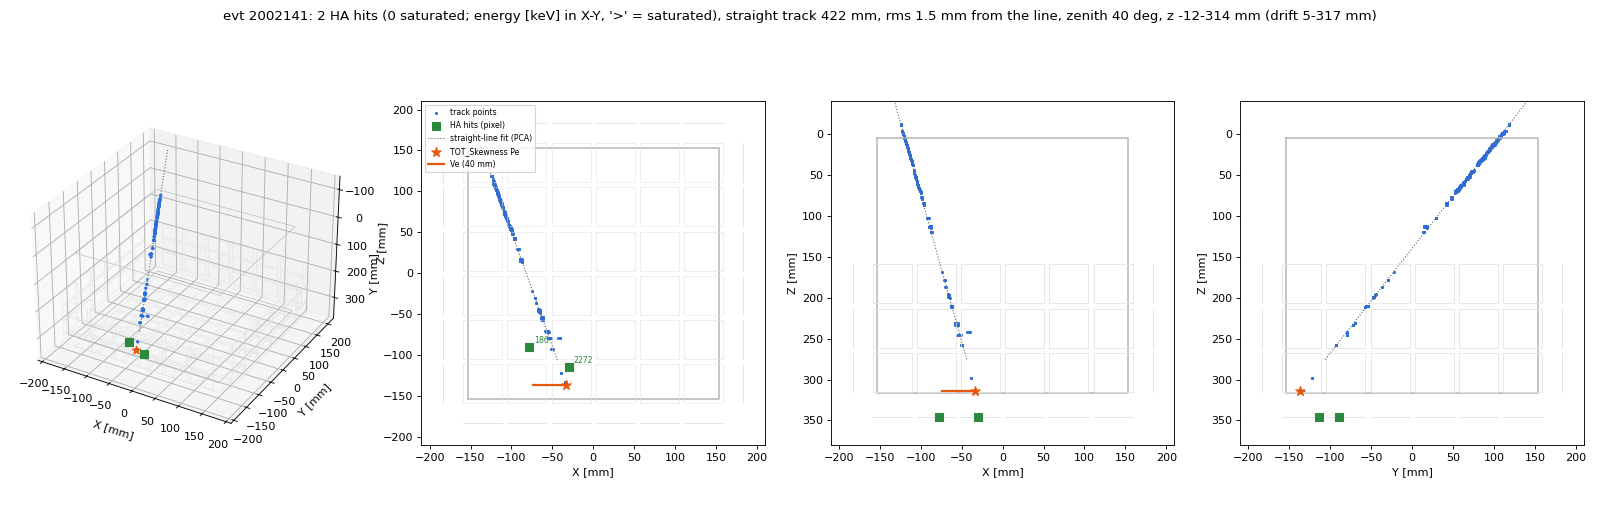

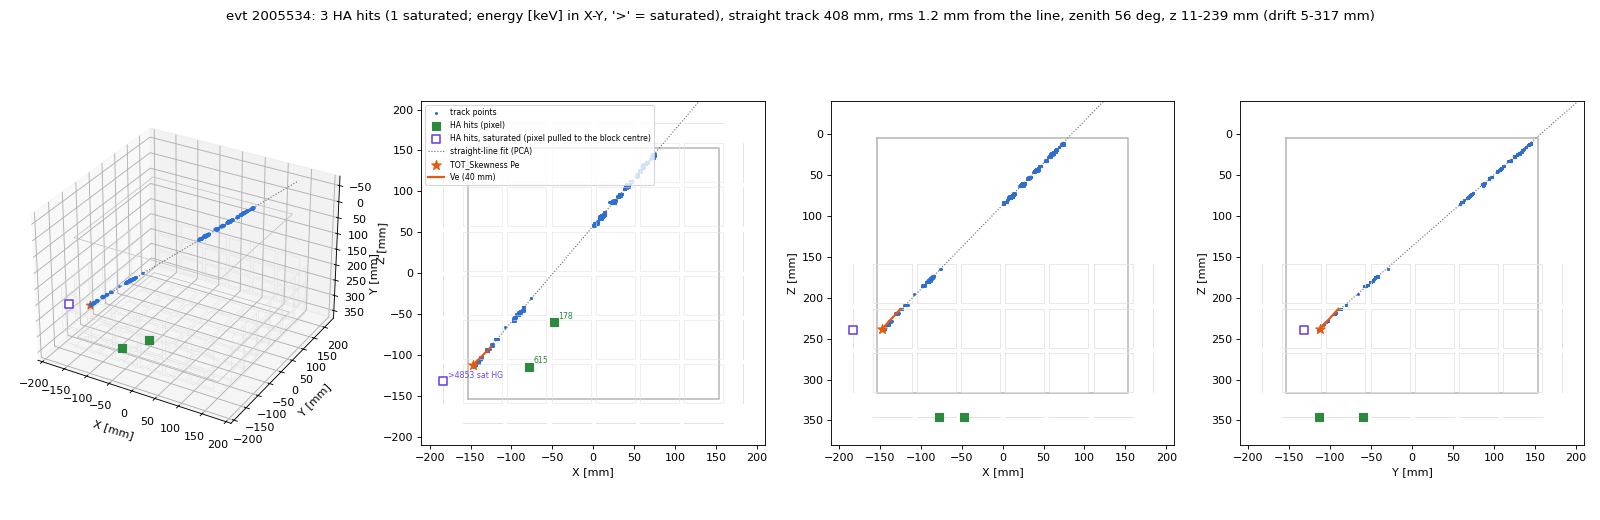

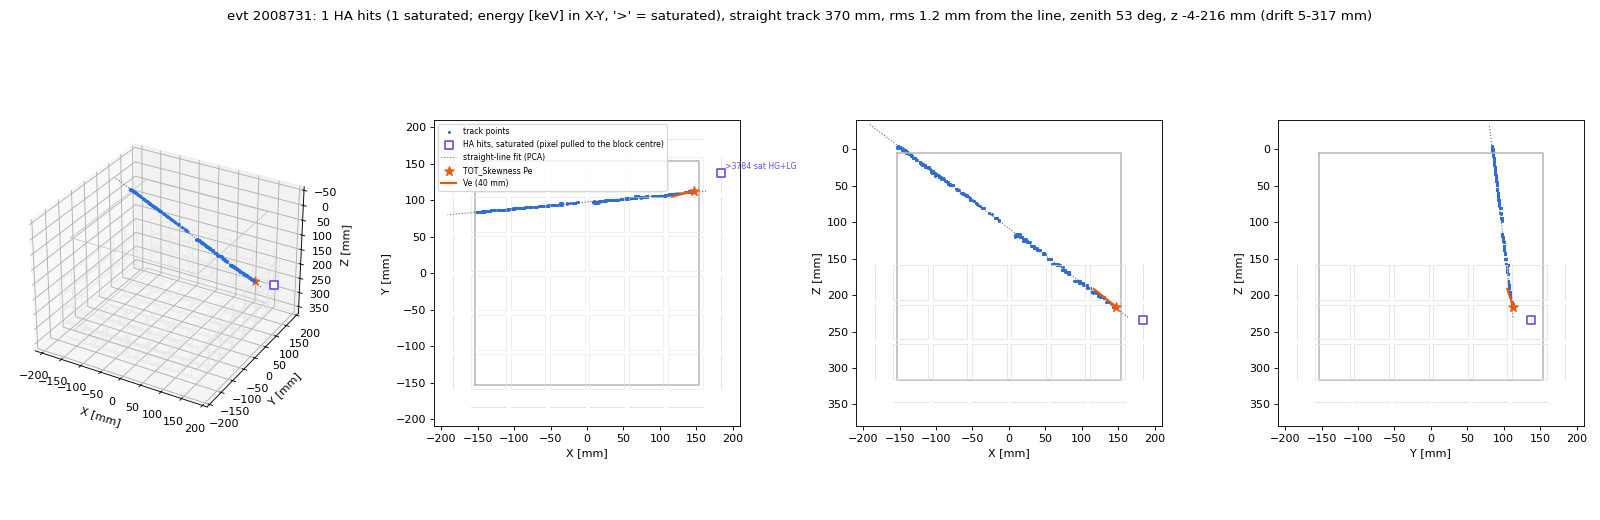

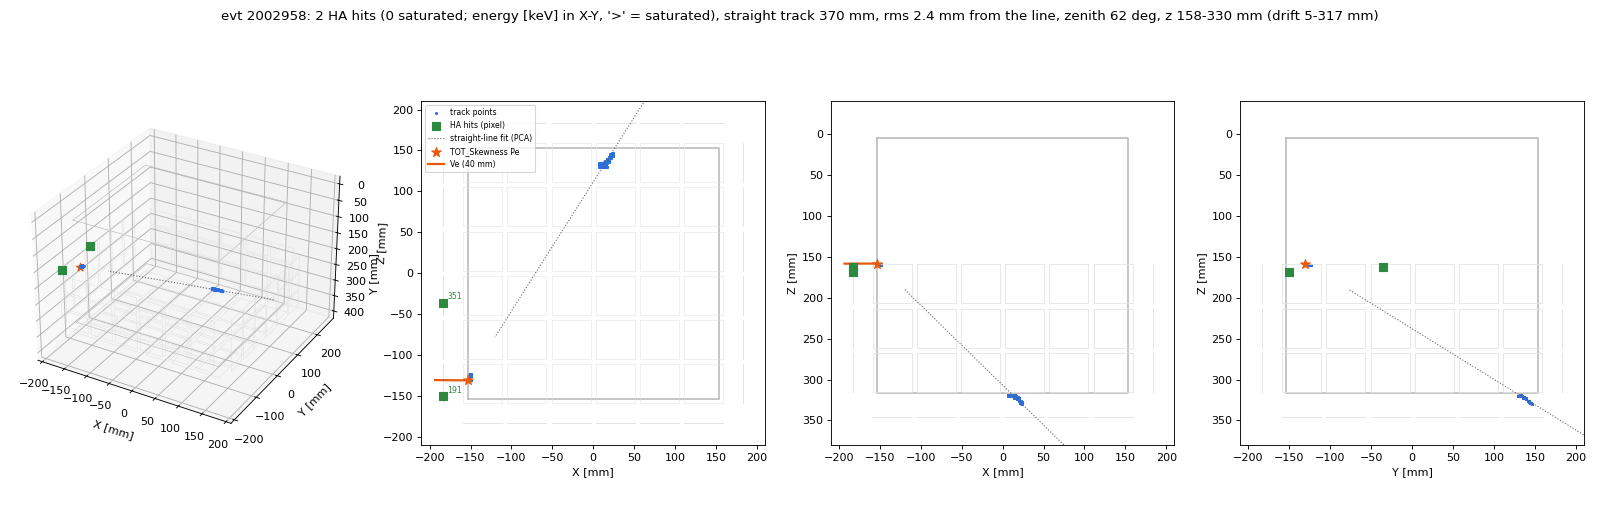

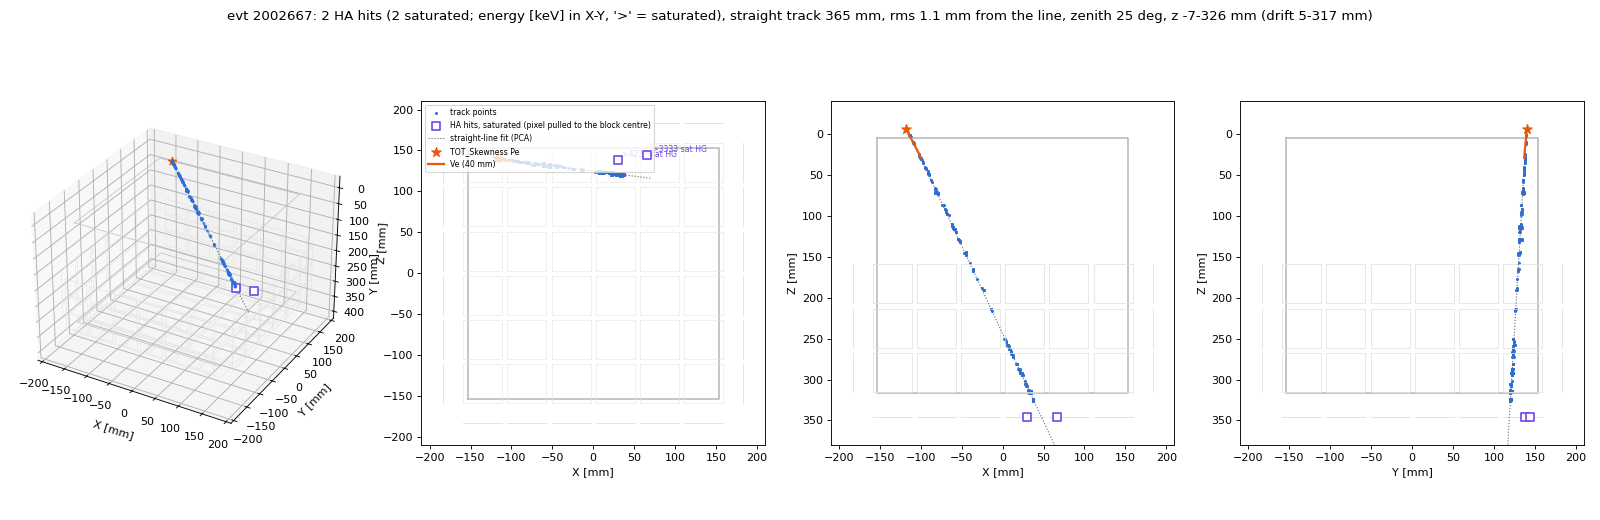

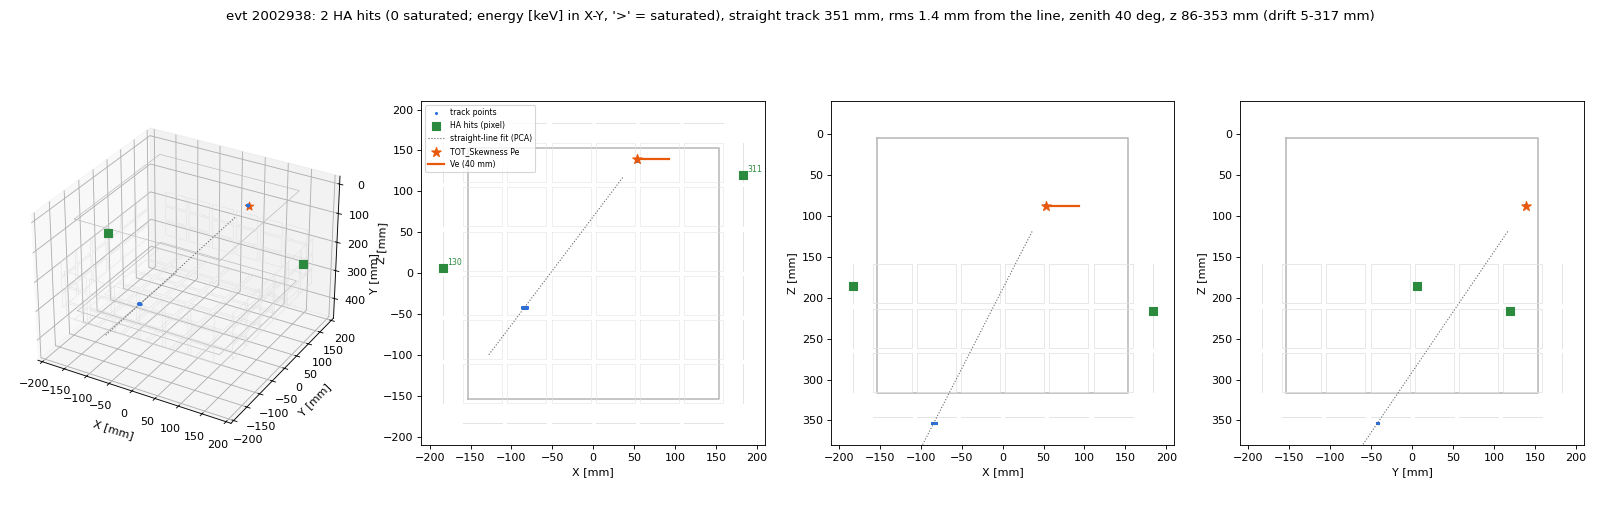

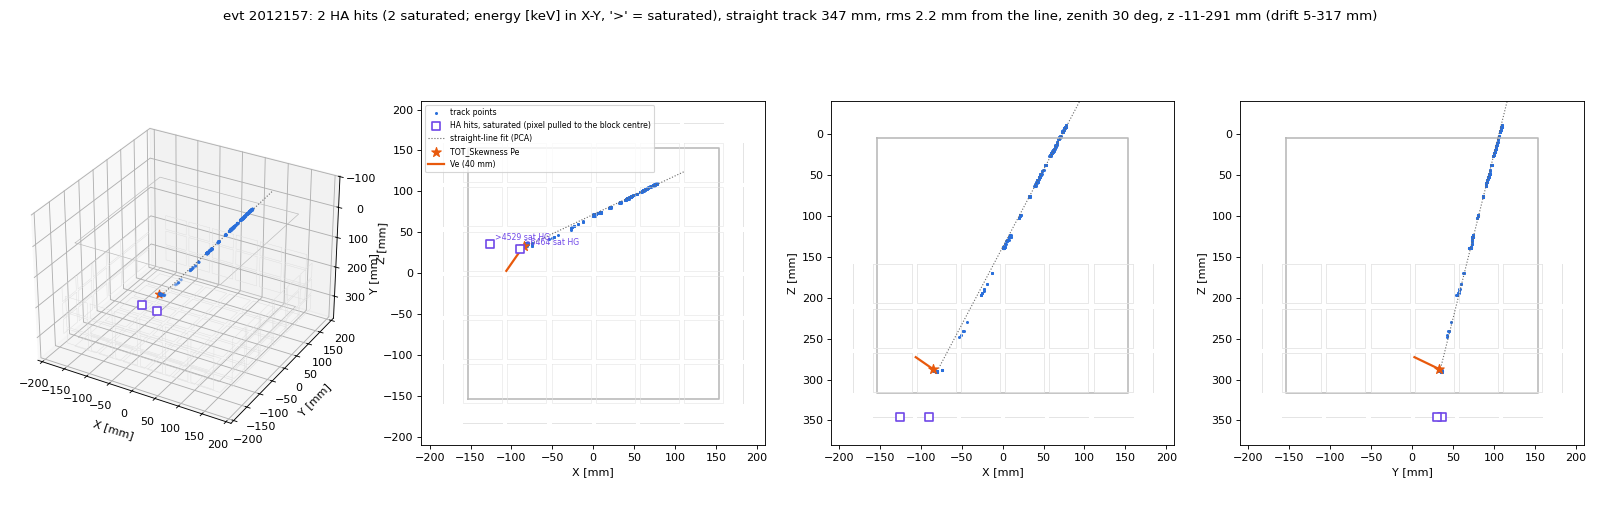

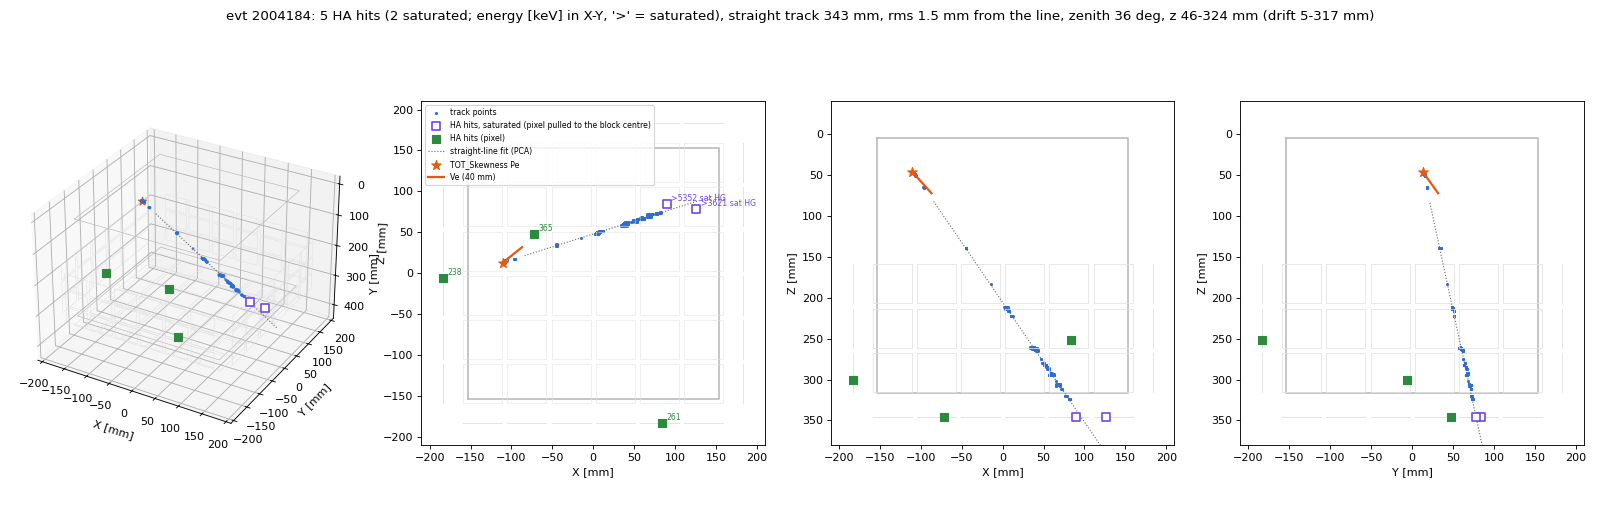

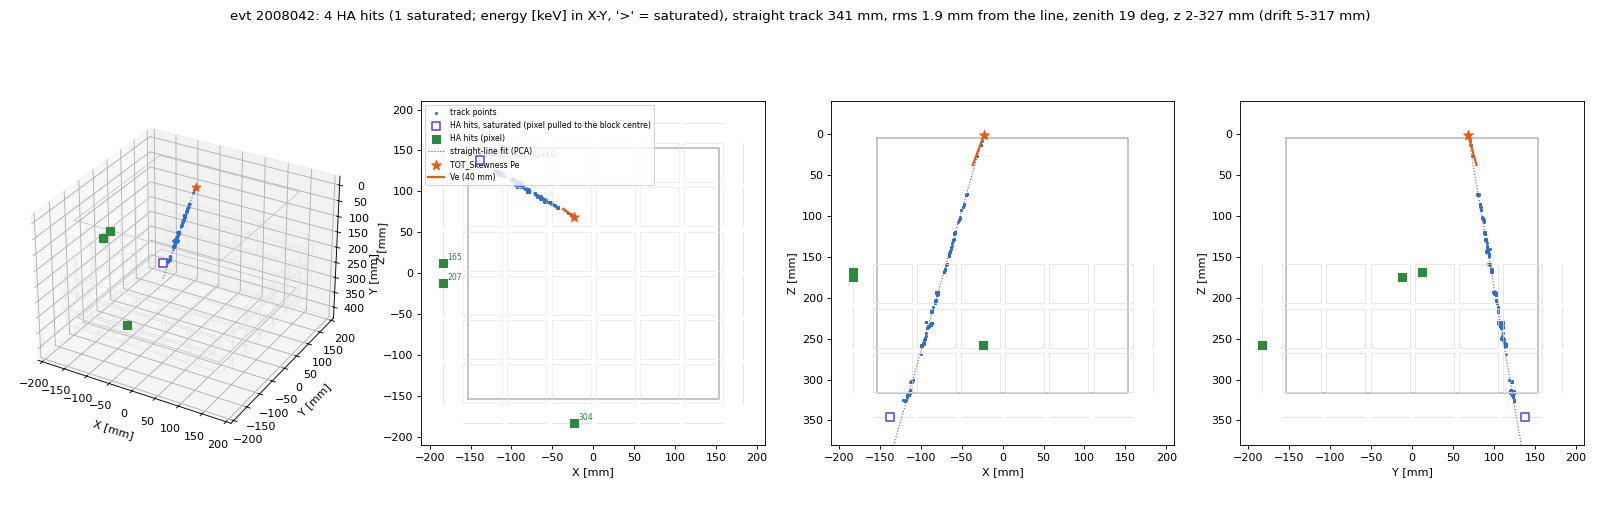

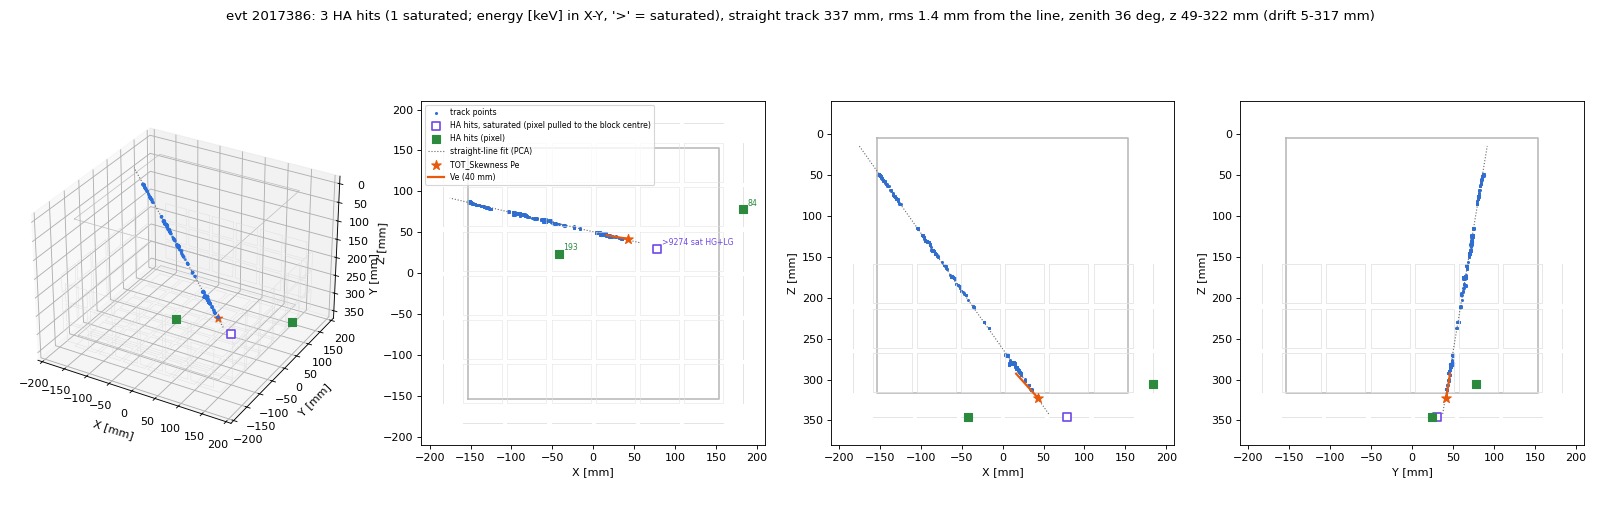

In [5]:
N_PLOT = 10
for r in tracks[:N_PLOT]:
    path = pm.plot_track(r, ha.get(r["evt"], []), geo, str(OUT / f"muon_evt{r['evt']}.png"))
    display(Image(filename=path))

実行例(20261115 run03、2,000,000 行目から 2 万行、直線の長い順に 10 本。4 本目と 6 本目は離れた塊をつないだもので、1 本の飛跡ではない):

![](figures/ETCC_MuonTracks_1.png)

![](figures/ETCC_MuonTracks_2.png)

![](figures/ETCC_MuonTracks_3.png)

![](figures/ETCC_MuonTracks_4.png)

![](figures/ETCC_MuonTracks_5.png)

![](figures/ETCC_MuonTracks_6.png)

![](figures/ETCC_MuonTracks_7.png)

![](figures/ETCC_MuonTracks_8.png)

![](figures/ETCC_MuonTracks_9.png)

![](figures/ETCC_MuonTracks_10.png)



## 5. 注意

- 飛跡は TOT_Skewness の座標(μPIC の中心が原点、Z はドリフトの向き)、HA は `geometry.csv` の座標で描いています。
  20 万行の直線の飛跡で、飛跡の通った HA のブロックと 1 MeV 以上(か飽和した)ヒットのブロックは底面 96 %・側面 91 % 一致し、μPIC の境目(upic1|2、upic3|2)をまたぐ飛跡は段差 1〜2 mm・角度 1.5° でつながりました(2026-11-20、AGENTS.md)。
  ピクセル単位(飽和していないヒットの位置)はまだ合わせ切れていません。
- 長い飛跡には、別々の塊(別の飛跡やノイズ)をまとめたものも混じります。`MAX_RMS` を小さくすると、1 本の直線に近いものだけになります。
- 20261115 run03 の 2 万イベントで、直線の長い飛跡は約 100 個でした。そのうちの 60 個で、HA のヒット(1 MeV 超)と直線の距離の中央値は 80 mm(関係のないイベントのヒットとなら 150 mm)でした。